In [1]:
import sys
from pathlib import Path

def find_project_root(start):
    for base in [start, *start.parents]:
        for candidate in [base, base / "barrier-extraction"]:
            if (candidate / "src").is_dir() and (candidate / "data").is_dir():
                return candidate
    raise FileNotFoundError("Could not locate barrier-extraction project root containing src/ and data/.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
PLOT_DIR = PROJECT_ROOT / "plots"
PLOT_DIR.mkdir(exist_ok=True)
EXPERIMENT_DATA_DIR = DATA_DIR / "experimental"
#import jax
#mport jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
#import autobnn
#from autobnn import estimators, training_util
#from autobnn import kernels, likelihoods

from src.utils import barrier_dist
from src.plot import plot_D_f


/opt/software-current/2023.06/x86_64/intel/skylake_avx512/software/Python-bundle-PyPI/2023.06-GCCcore-12.3.0/lib/python3.11/site-packages/pyparsing/core.py:5596: SyntaxWarning: 'return' in a 'finally' block
  return self.__class__.__name__ + ": " + retString


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.wong import sigma
import scienceplots
plt.style.use(['science', 'no-latex', 'ieee'])

plt.rc('axes', labelsize=14) 
plt.rcParams['axes.titlesize'] = 20
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
plt.rc('legend', fontsize=10)  
plt.rc('lines', linewidth=2)


import scipy as sp
import os
from scipy.optimize import curve_fit
import findiff as fd

<>:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/ipykernel_1038440/1780867083.py:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  tmpdf = pd.read_csv(os.path.join(dirname,file),sep='\s+',names=['Ecm','Sigma','Error'])


Best-fit parameters:
  E0    = 73.3846 ± 0.0047 MeV
  R0    = 10.2260 ± 0.0078 fm
  hbarw = 4.8410 ± 0.0074 MeV


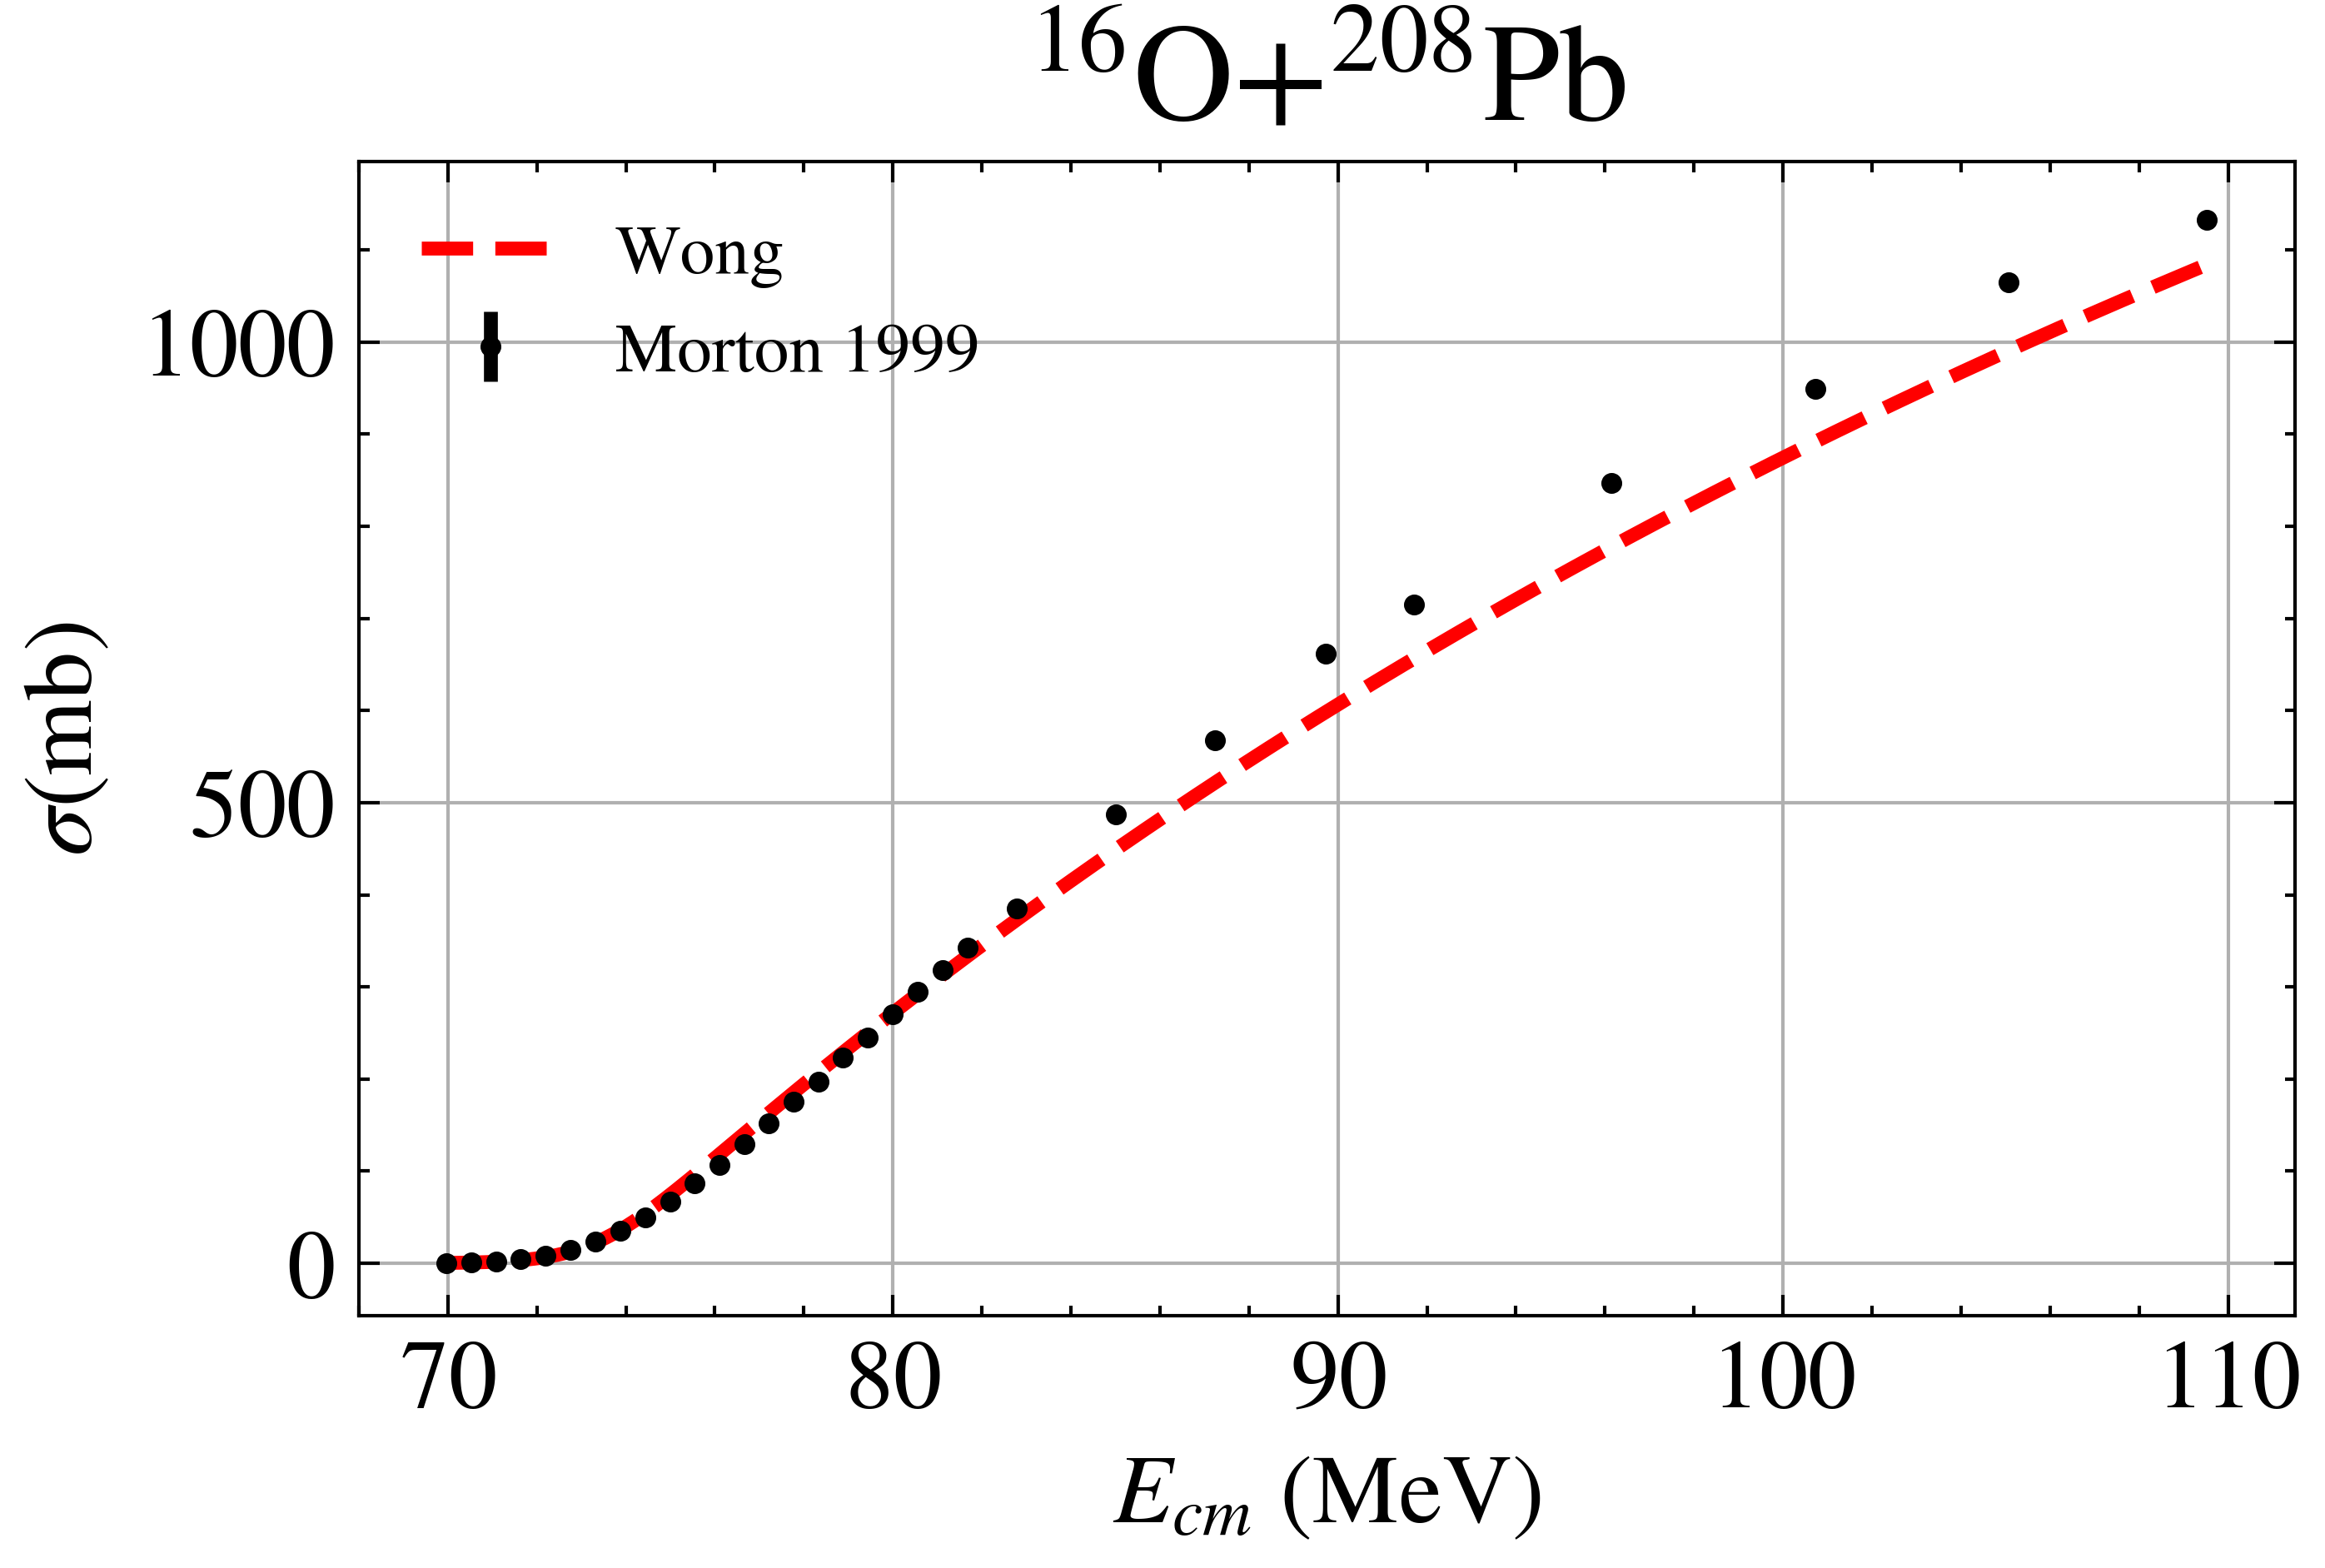

In [3]:
dirname = EXPERIMENT_DATA_DIR / "16O208Pb_exp"
system = "$^{208}$Pb+$^{16}$O"
fileprefix = dirname

expfiles = [ 'expMort.dat', 'expDas.dat' ]
explabel = [ 'Morton et al. 1999', 'Dasgupta et al. 2007' ]
expmarker = [ 'o', 's' ]
expcolor = [ 'k', 'g' ]

exp = []

for file in expfiles:
    tmpdf = pd.read_csv(os.path.join(dirname,file),sep='\s+',names=['Ecm','Sigma','Error'])
    if(tmpdf['Ecm'].iloc[0] > tmpdf['Ecm'].iloc[-1]):
        exp.append(tmpdf.iloc[::-1])
    else:
        exp.append(tmpdf)

xmin = 70.0
xmax = 90.0


E_data = exp[0]['Ecm'].to_numpy()
Sigma_data = exp[0]['Sigma'].to_numpy()
Sigma_err  = exp[0]['Error'].to_numpy()


# --- Initial guesses for [E0, R0, hbarw] ---
# You may need to tweak these based on your system.
initial_guess = [70.0, 11.0, 4]  # e.g. E0≈10MeV, R0≈7fm, ħω≈4MeV

# --- Perform the fit ---
popt, pcov = curve_fit(
    sigma,
    E_data,
    Sigma_data,
    p0=initial_guess,
    sigma=Sigma_err,
    absolute_sigma=True,
    # bounds can help keep parameters physical:
    bounds=([0.0, 8.0, 0.0], [np.inf, 15.0, np.inf])
)

E0_opt, R0_opt, hbarw_opt = popt
perr = np.sqrt(np.diag(pcov))

print(f"Best-fit parameters:")
print(f"  E0    = {E0_opt:.4f} ± {perr[0]:.4f} MeV")
print(f"  R0    = {R0_opt:.4f} ± {perr[1]:.4f} fm")
print(f"  hbarw = {hbarw_opt:.4f} ± {perr[2]:.4f} MeV")

# --- Plot experiment vs. fit ---
E_plot = np.linspace(E_data.min(), E_data.max(), 500)
Sigma_fit = sigma(E_plot, E0_opt, R0_opt, hbarw_opt)

plt.figure(figsize=(5,3))
plt.errorbar(E_data, Sigma_data, yerr=Sigma_err, fmt='o', label='Morton 1999', markersize=2)
#plt.scatter(E_data, Sigma_data, label='Morton 1999', color='k', s=10)
plt.plot(E_plot, Sigma_fit, label='Wong')
plt.xlabel(r'$E_{cm}$ (MeV)')
plt.ylabel(r'$\sigma$(mb)')
plt.title("$^{16}$O+$^{208}$Pb")
plt.legend()
plt.grid(True)
#plt.tight_layout()
plt.show()

In [4]:
N = 1000
total_E = np.concatenate((exp[0]['Ecm'].to_numpy(), exp[1]['Ecm'].to_numpy()))
E_fine = np.linspace(total_E.min(), total_E.max(), N)

sigma_mean = sigma(E_fine, E0_opt, R0_opt, hbarw_opt )
E_eval   = np.linspace(E_fine.min() - 5, E_fine.max() + 5, 500)
n_samples = 100

# PRECOMPUTE TRUE D_f(E) ON THE FINE GRID
true_d = barrier_dist(
    E_fine,
    sigma(E_fine, E0_opt, R0_opt, hbarw_opt),
    acc=4
)

In [5]:
# ---------- LaTeX-ready AutoBNN comparison helpers ----------
TRUE_COLOR = "tab:blue"
BNN_COLOR = "tab:green"
DATA_COLOR = "0.15"
BAND_ALPHA = 0.22
SHARED_LABEL_FONTSIZE = 24
SHARED_XLABEL_Y = 0.06
SHARED_YLABEL_X = 0.1

MODEL_SPECS = [
    ("Changepoint of Safe Products", "changepoint_of_safe_products"),
    ("Sum of Changepoints", "sum_of_changepoints"),
    ("Sum of Products", "sum_of_products"),
    ("Sum of Stumps", "sum_of_stumps"),
]

BNN_SECOND_DERIV_DIR = PROJECT_ROOT / "data" / "results" / "autobnn_ch3_second_derivs"

def bnn_second_deriv_path(folder, slug):
    return BNN_SECOND_DERIV_DIR / folder / f"second_derivs_{slug}_normal_likelihood_lognormal_noise.npy"


def load_bnn_case(folder, e_train_file, e_pred_file=None):
    E_train = np.load(DATA_DIR / e_train_file)
    preds = {
        name: np.load(bnn_second_deriv_path(folder, slug))
        for name, slug in MODEL_SPECS
    }
    n_pred = next(iter(preds.values())).shape[-1]
    if e_pred_file is None:
        E_pred = np.arange(E_train[0] - 5, E_train[-1] + 5, 0.2)
    else:
        E_pred = np.load(DATA_DIR / e_pred_file)
    if E_pred.size != n_pred:
        E_pred = np.linspace(E_pred[0], E_pred[-1], n_pred)
    return {
        "folder": folder,
        "E_train": E_train,
        "E_pred": E_pred,
        "preds": preds,
    }


def add_panel_label(ax, label, loc="upper left"):
    if loc == "lower left":
        x, y, va = 0.03, 0.08, "bottom"
    else:
        x, y, va = 0.03, 0.92, "top"
    ax.text(
        x,
        y,
        label,
        transform=ax.transAxes,
        ha="left",
        va=va,
        fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.5),
    )


def bnn_legend_handles():
    return [
        plt.Line2D([], [], color=TRUE_COLOR, lw=2.0, label="True"),
        plt.Line2D([], [], color=BNN_COLOR, lw=2.0, ls="--", label="BNN mean"),
        plt.Rectangle((0, 0), 1, 1, color=BNN_COLOR, alpha=BAND_ALPHA, label="BNN 95% CI"),
        plt.Line2D([], [], marker="o", color=DATA_COLOR, lw=0, markersize=4, label="Train pts"),
    ]


def add_inset_legend(ax, handles):
    ax.legend(
        handles=handles,
        loc="upper right",
        bbox_to_anchor=(0.98, 0.98),
        bbox_transform=ax.transAxes,
        frameon=True,
        framealpha=0.88,
        facecolor="white",
        edgecolor="0.75",
        fontsize=8,
        handlelength=1.6,
        borderpad=0.35,
        labelspacing=0.3,
    )


def plot_bnn_comparison_grid(column_specs, outfile, suptitle=None, panel_label_loc="upper left"):
    nrows, ncols = len(MODEL_SPECS), len(column_specs)
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.2, 2.35 * nrows), sharex=True, sharey=True)
    axes = np.asarray(axes).reshape(nrows, ncols)

    for col, (column_title, case) in enumerate(column_specs):
        axes[0, col].set_title(column_title, fontsize=12)
        E_train = case["E_train"]
        E_pred = case["E_pred"]
        true_d_train = np.interp(E_train, E_fine, true_d)
        for row, (model_name, _) in enumerate(MODEL_SPECS):
            ax = axes[row, col]
            preds = case["preds"][model_name]
            d_mean = preds.mean(axis=0)
            d_low, d_high = np.percentile(preds, [2.5, 97.5], axis=0)

            ax.plot(E_fine, true_d, lw=2.0, color=TRUE_COLOR)
            ax.plot(E_pred, d_mean, lw=2.0, ls="--", color=BNN_COLOR)
            ax.fill_between(E_pred, d_low, d_high, color=BNN_COLOR, alpha=BAND_ALPHA, linewidth=0)
            ax.scatter(E_train, true_d_train, s=9, color=DATA_COLOR, alpha=0.8, edgecolor="none", zorder=5)
            add_panel_label(ax, model_name, loc=panel_label_loc)
            ax.set_xlim(E_train[0], 90)
            ax.set_ylim(-1000, 1500)
            ax.tick_params(labelsize=9)

    if suptitle:
        fig.suptitle(suptitle, fontsize=12, y=0.995)
    fig.supylabel(r"$D_f(E)$ (mb/MeV)", fontsize=SHARED_LABEL_FONTSIZE, x=SHARED_YLABEL_X)
    add_inset_legend(axes[0, -1], bnn_legend_handles())
    fig.tight_layout(rect=[0.06, 0.09, 1, 0.965 if suptitle else 0.99])
    left = axes[-1, 0].get_position().x0
    right = axes[-1, -1].get_position().x1
    fig.text(0.5 * (left + right), SHARED_XLABEL_Y, r"$E_{\mathrm{cm}}$ (MeV)", ha="center", va="center", fontsize=SHARED_LABEL_FONTSIZE)
    fig.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


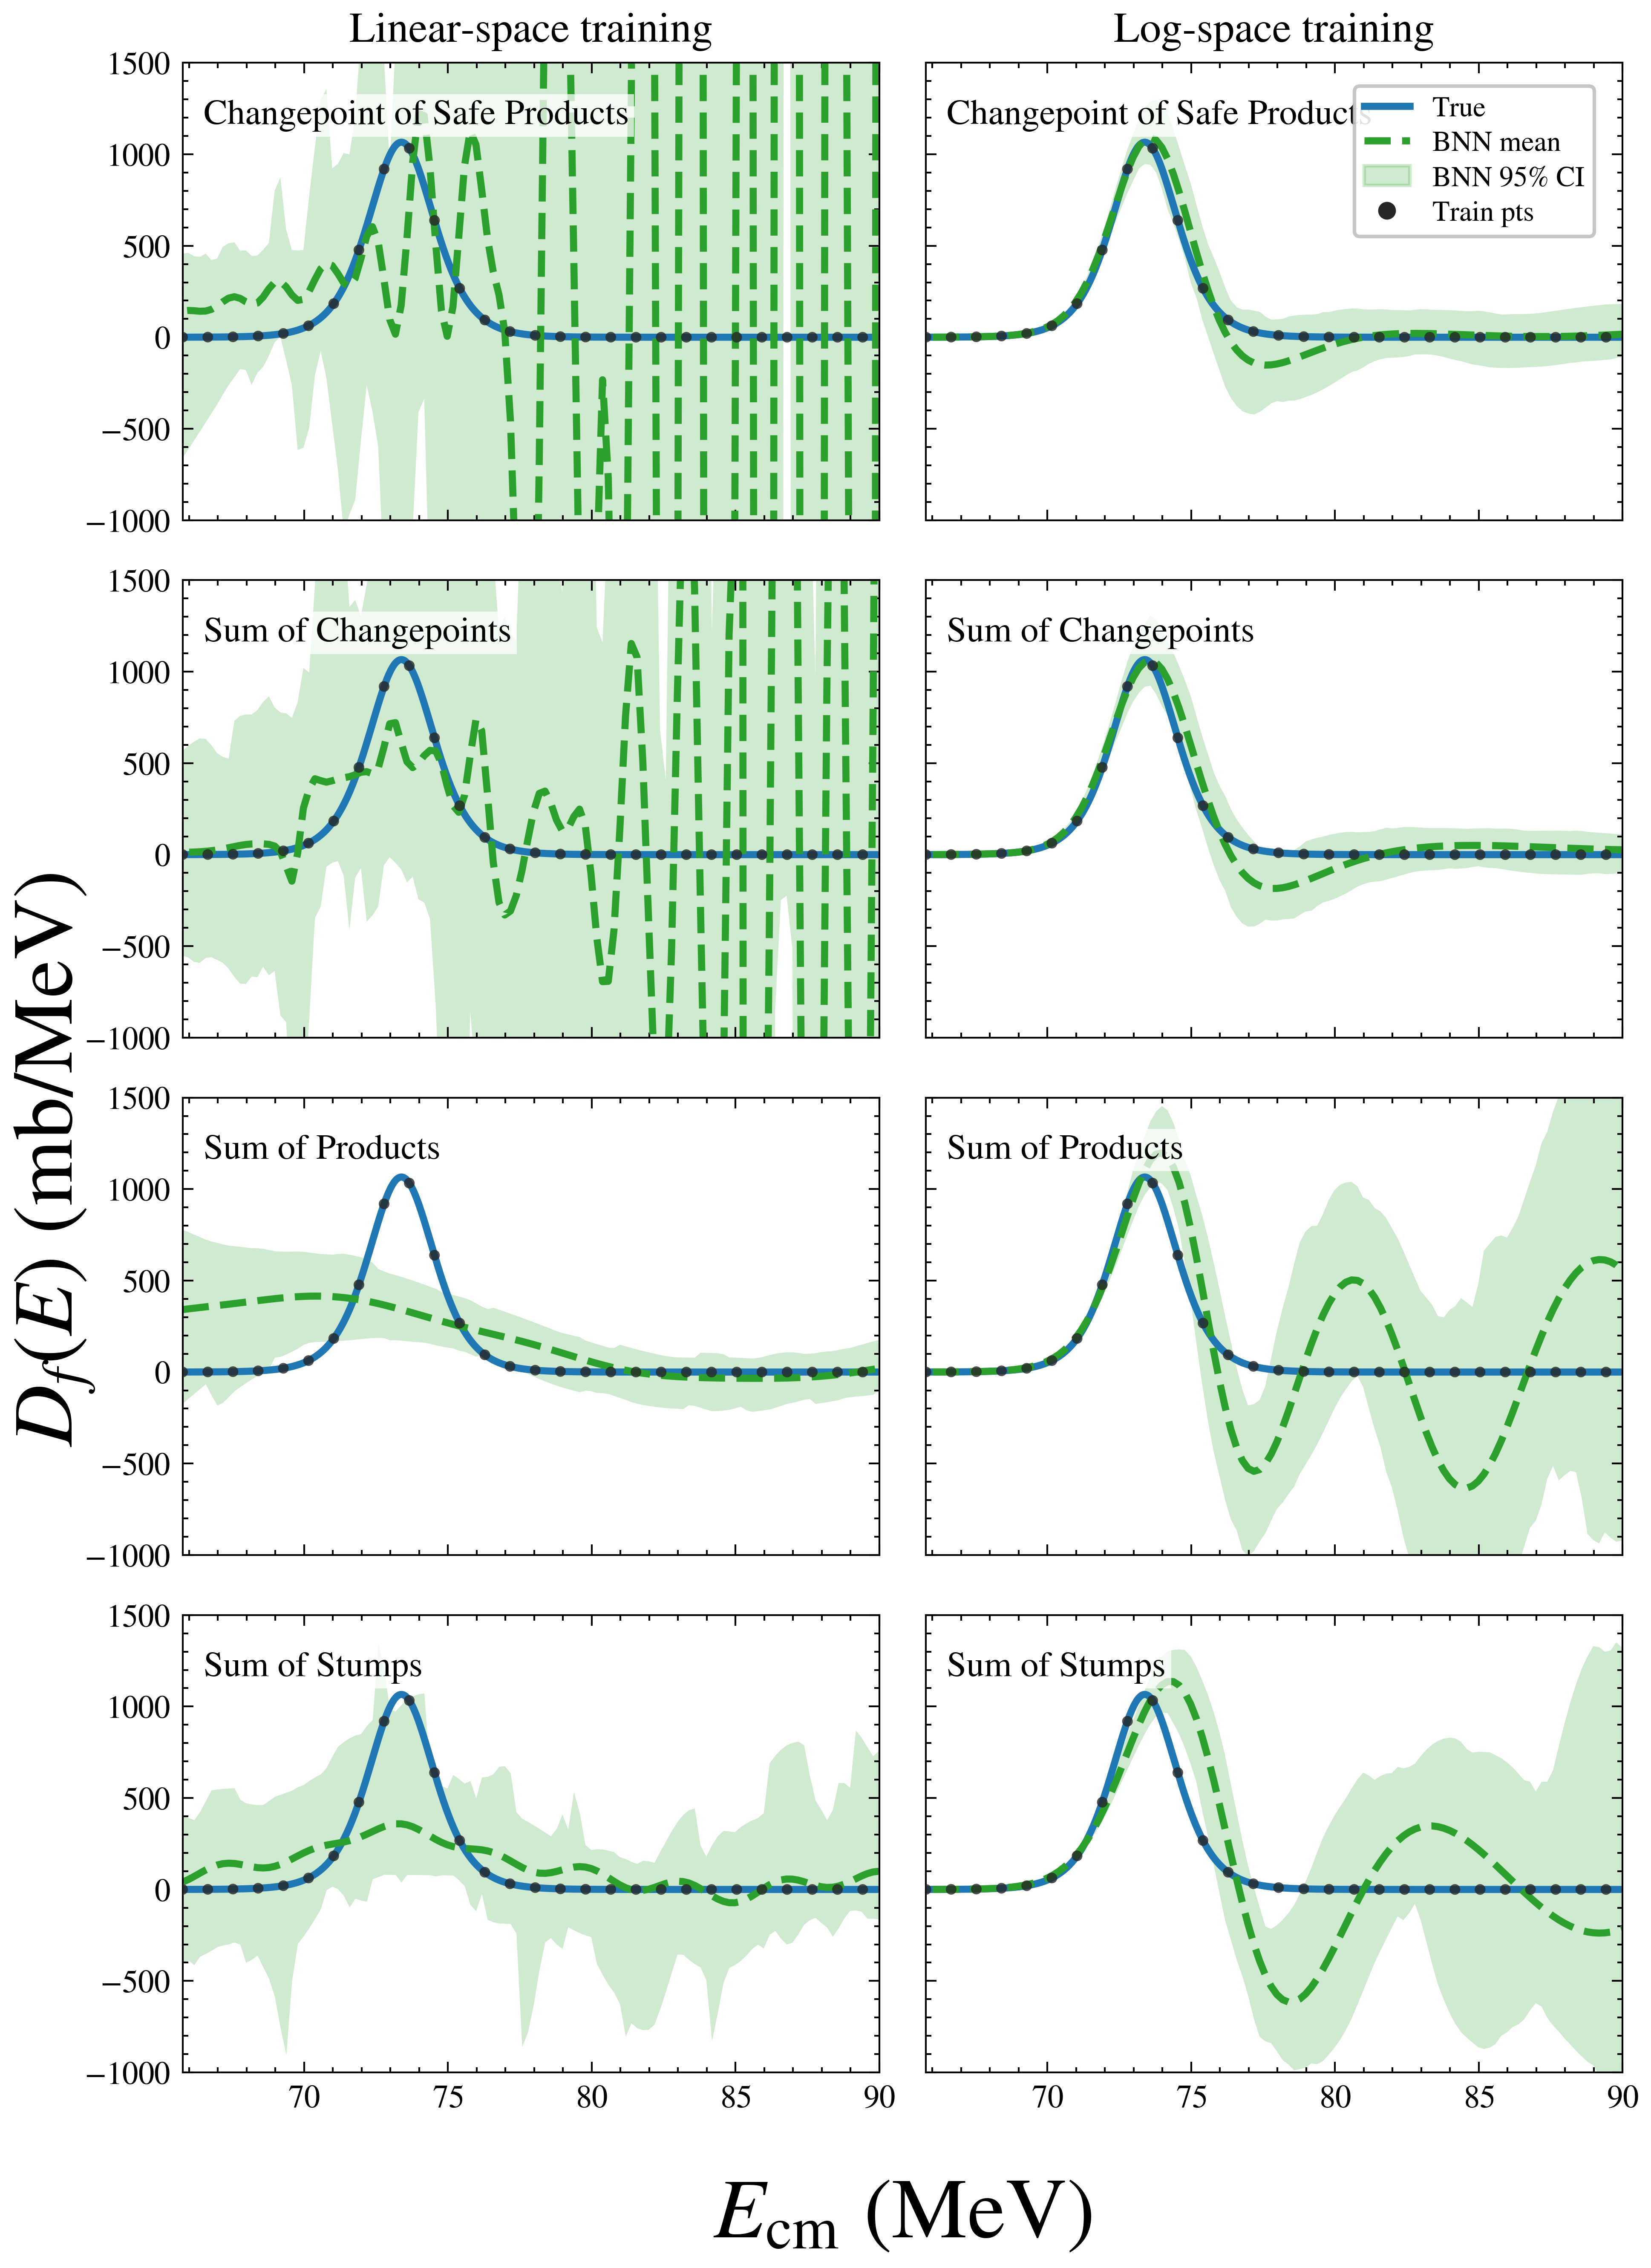

In [6]:
bnn_linear_20_1e1 = load_bnn_case("E_20_1e-1", "E_tr_20.npy")
bnn_log_20_1e1 = load_bnn_case("E_20_1e-1_log", "E_tr_20.npy")

plot_bnn_comparison_grid(
    [
        ("Linear-space training", bnn_linear_20_1e1),
        ("Log-space training", bnn_log_20_1e1),
    ],
    PLOT_DIR / "autobnn_linear_vs_log_grid.png",
    suptitle=None,
)


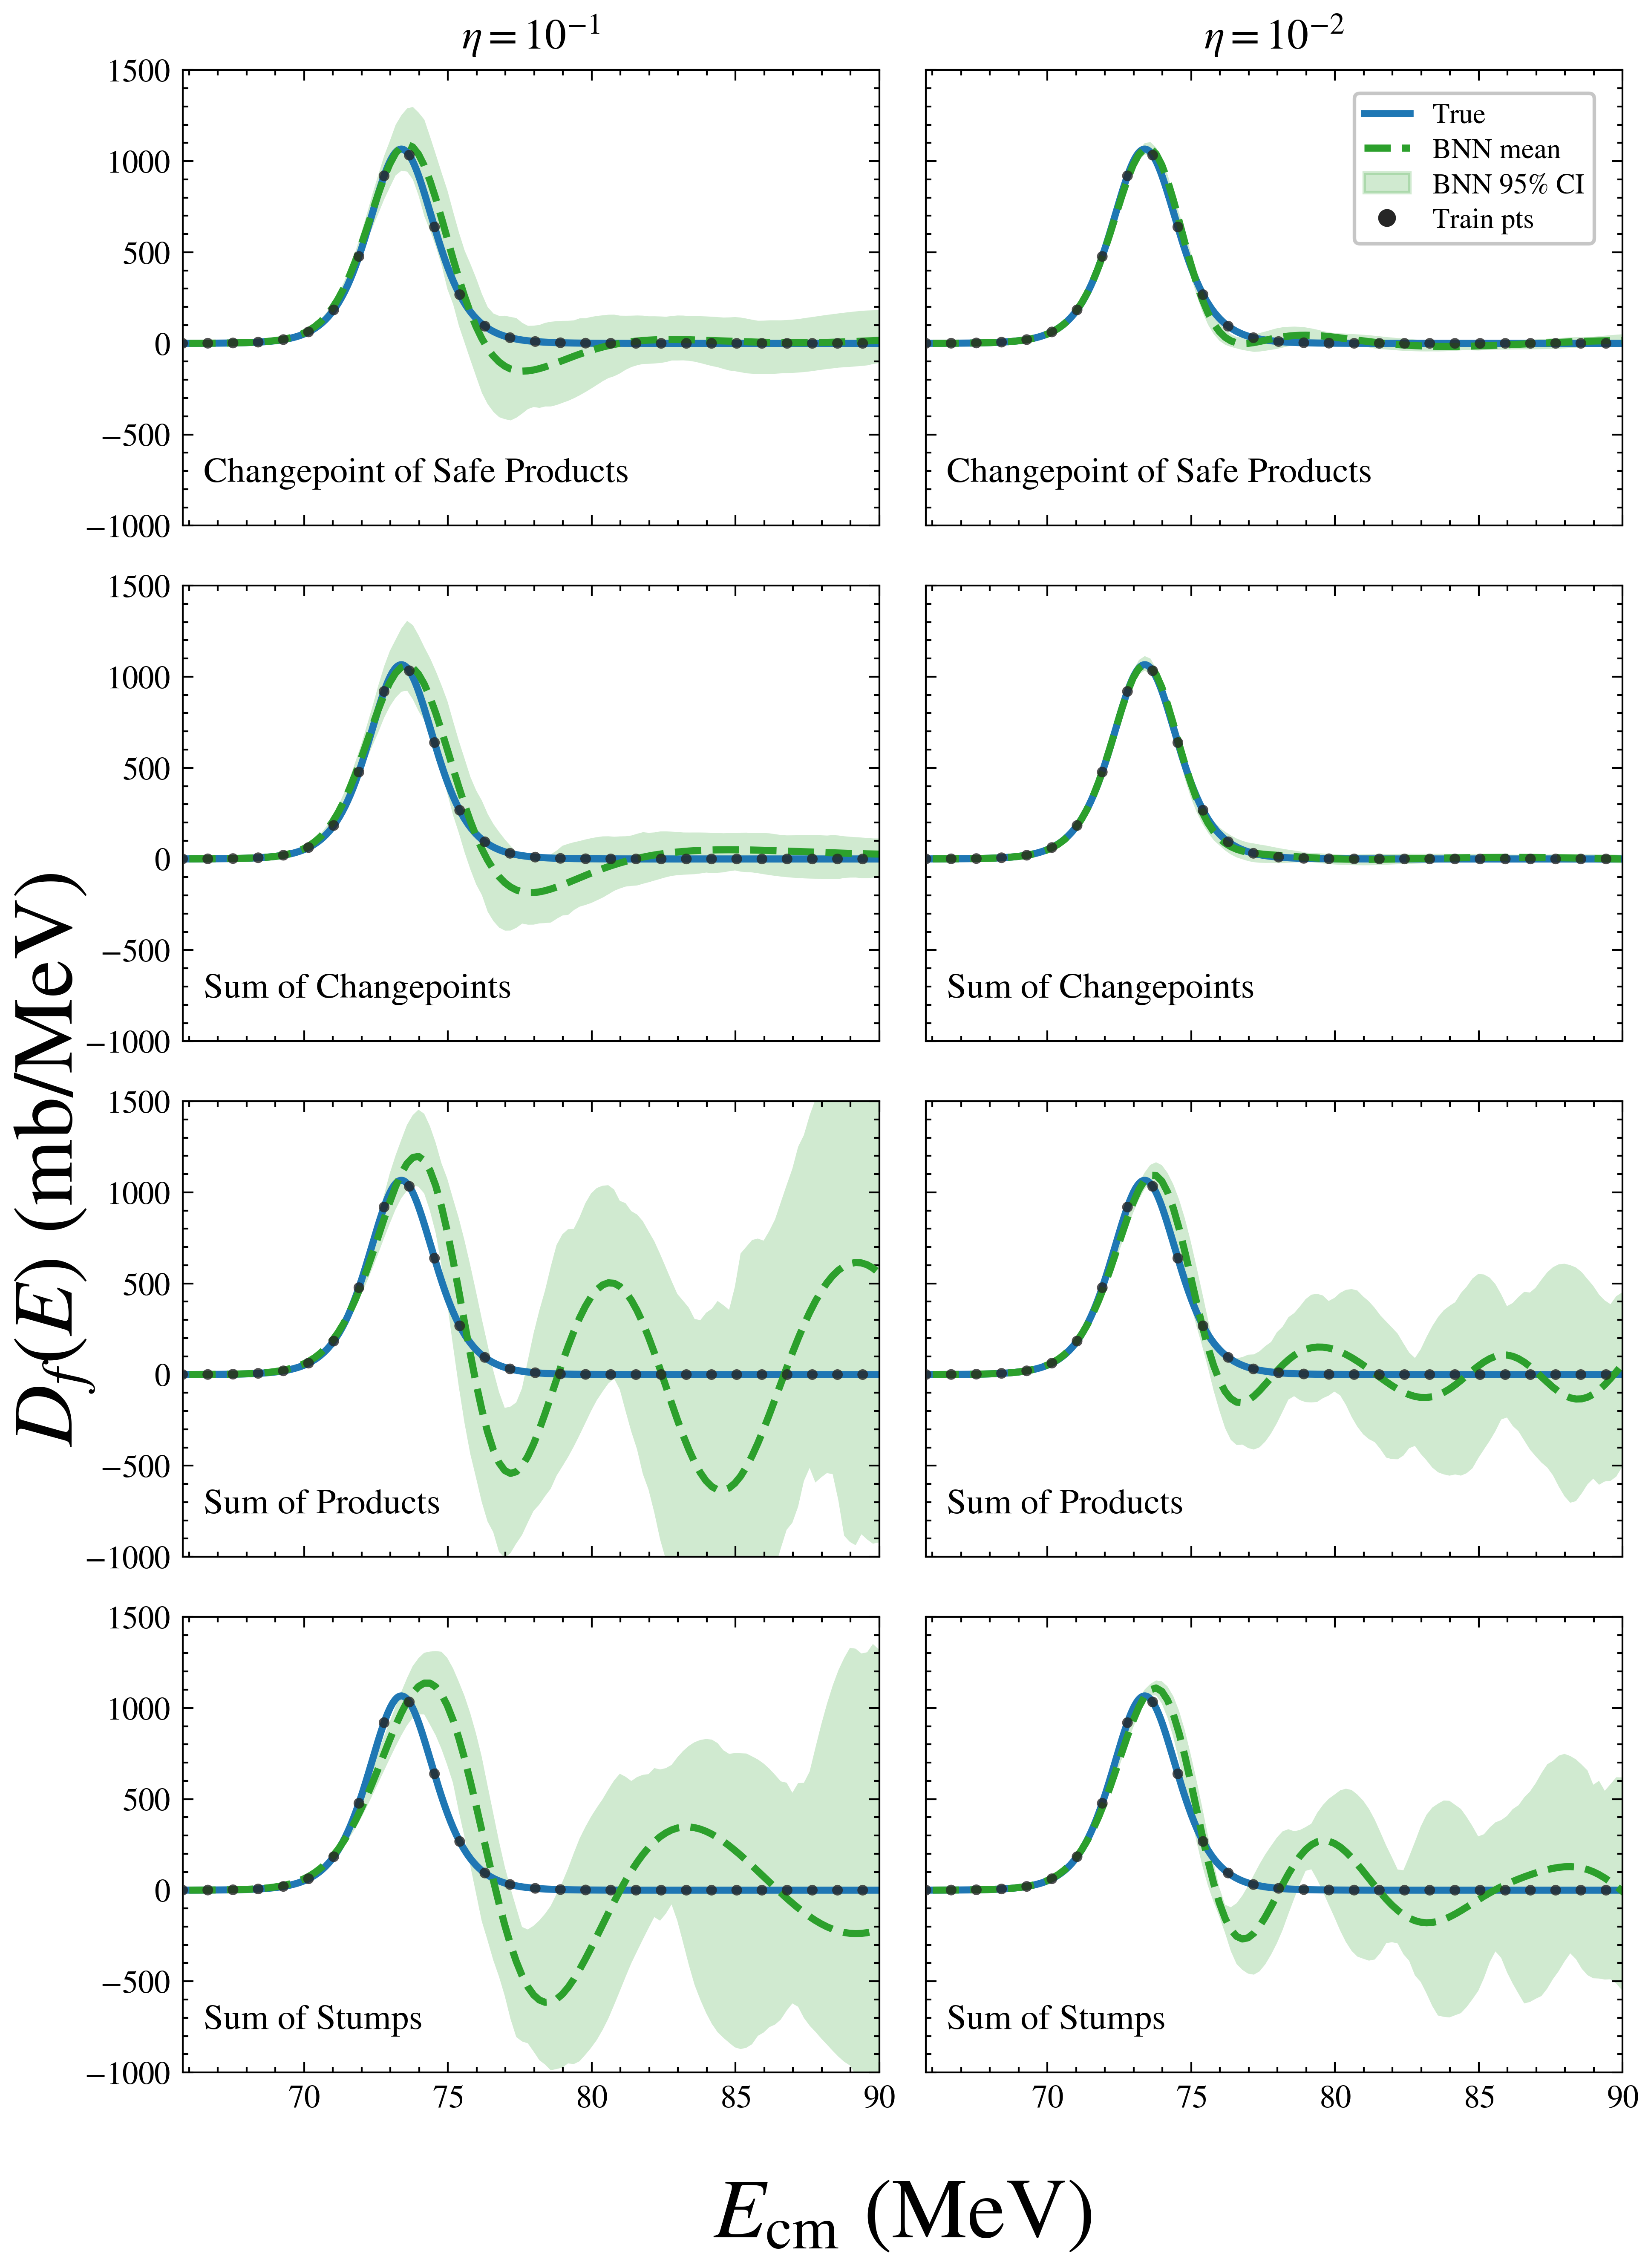

In [7]:
bnn_log_20_1e1 = load_bnn_case("E_20_1e-1_log", "E_tr_20.npy")
bnn_log_20_1e2 = load_bnn_case("E_20_1e-2_log", "E_tr_20.npy")

plot_bnn_comparison_grid(
    [
        (rf"$\eta = 10^{{-1}}$", bnn_log_20_1e1),
        (rf"$\eta = 10^{{-2}}$", bnn_log_20_1e2),
    ],
    PLOT_DIR / "autobnn_noise_ratio_grid_log.png",
    suptitle=None,
    panel_label_loc="lower left",
)


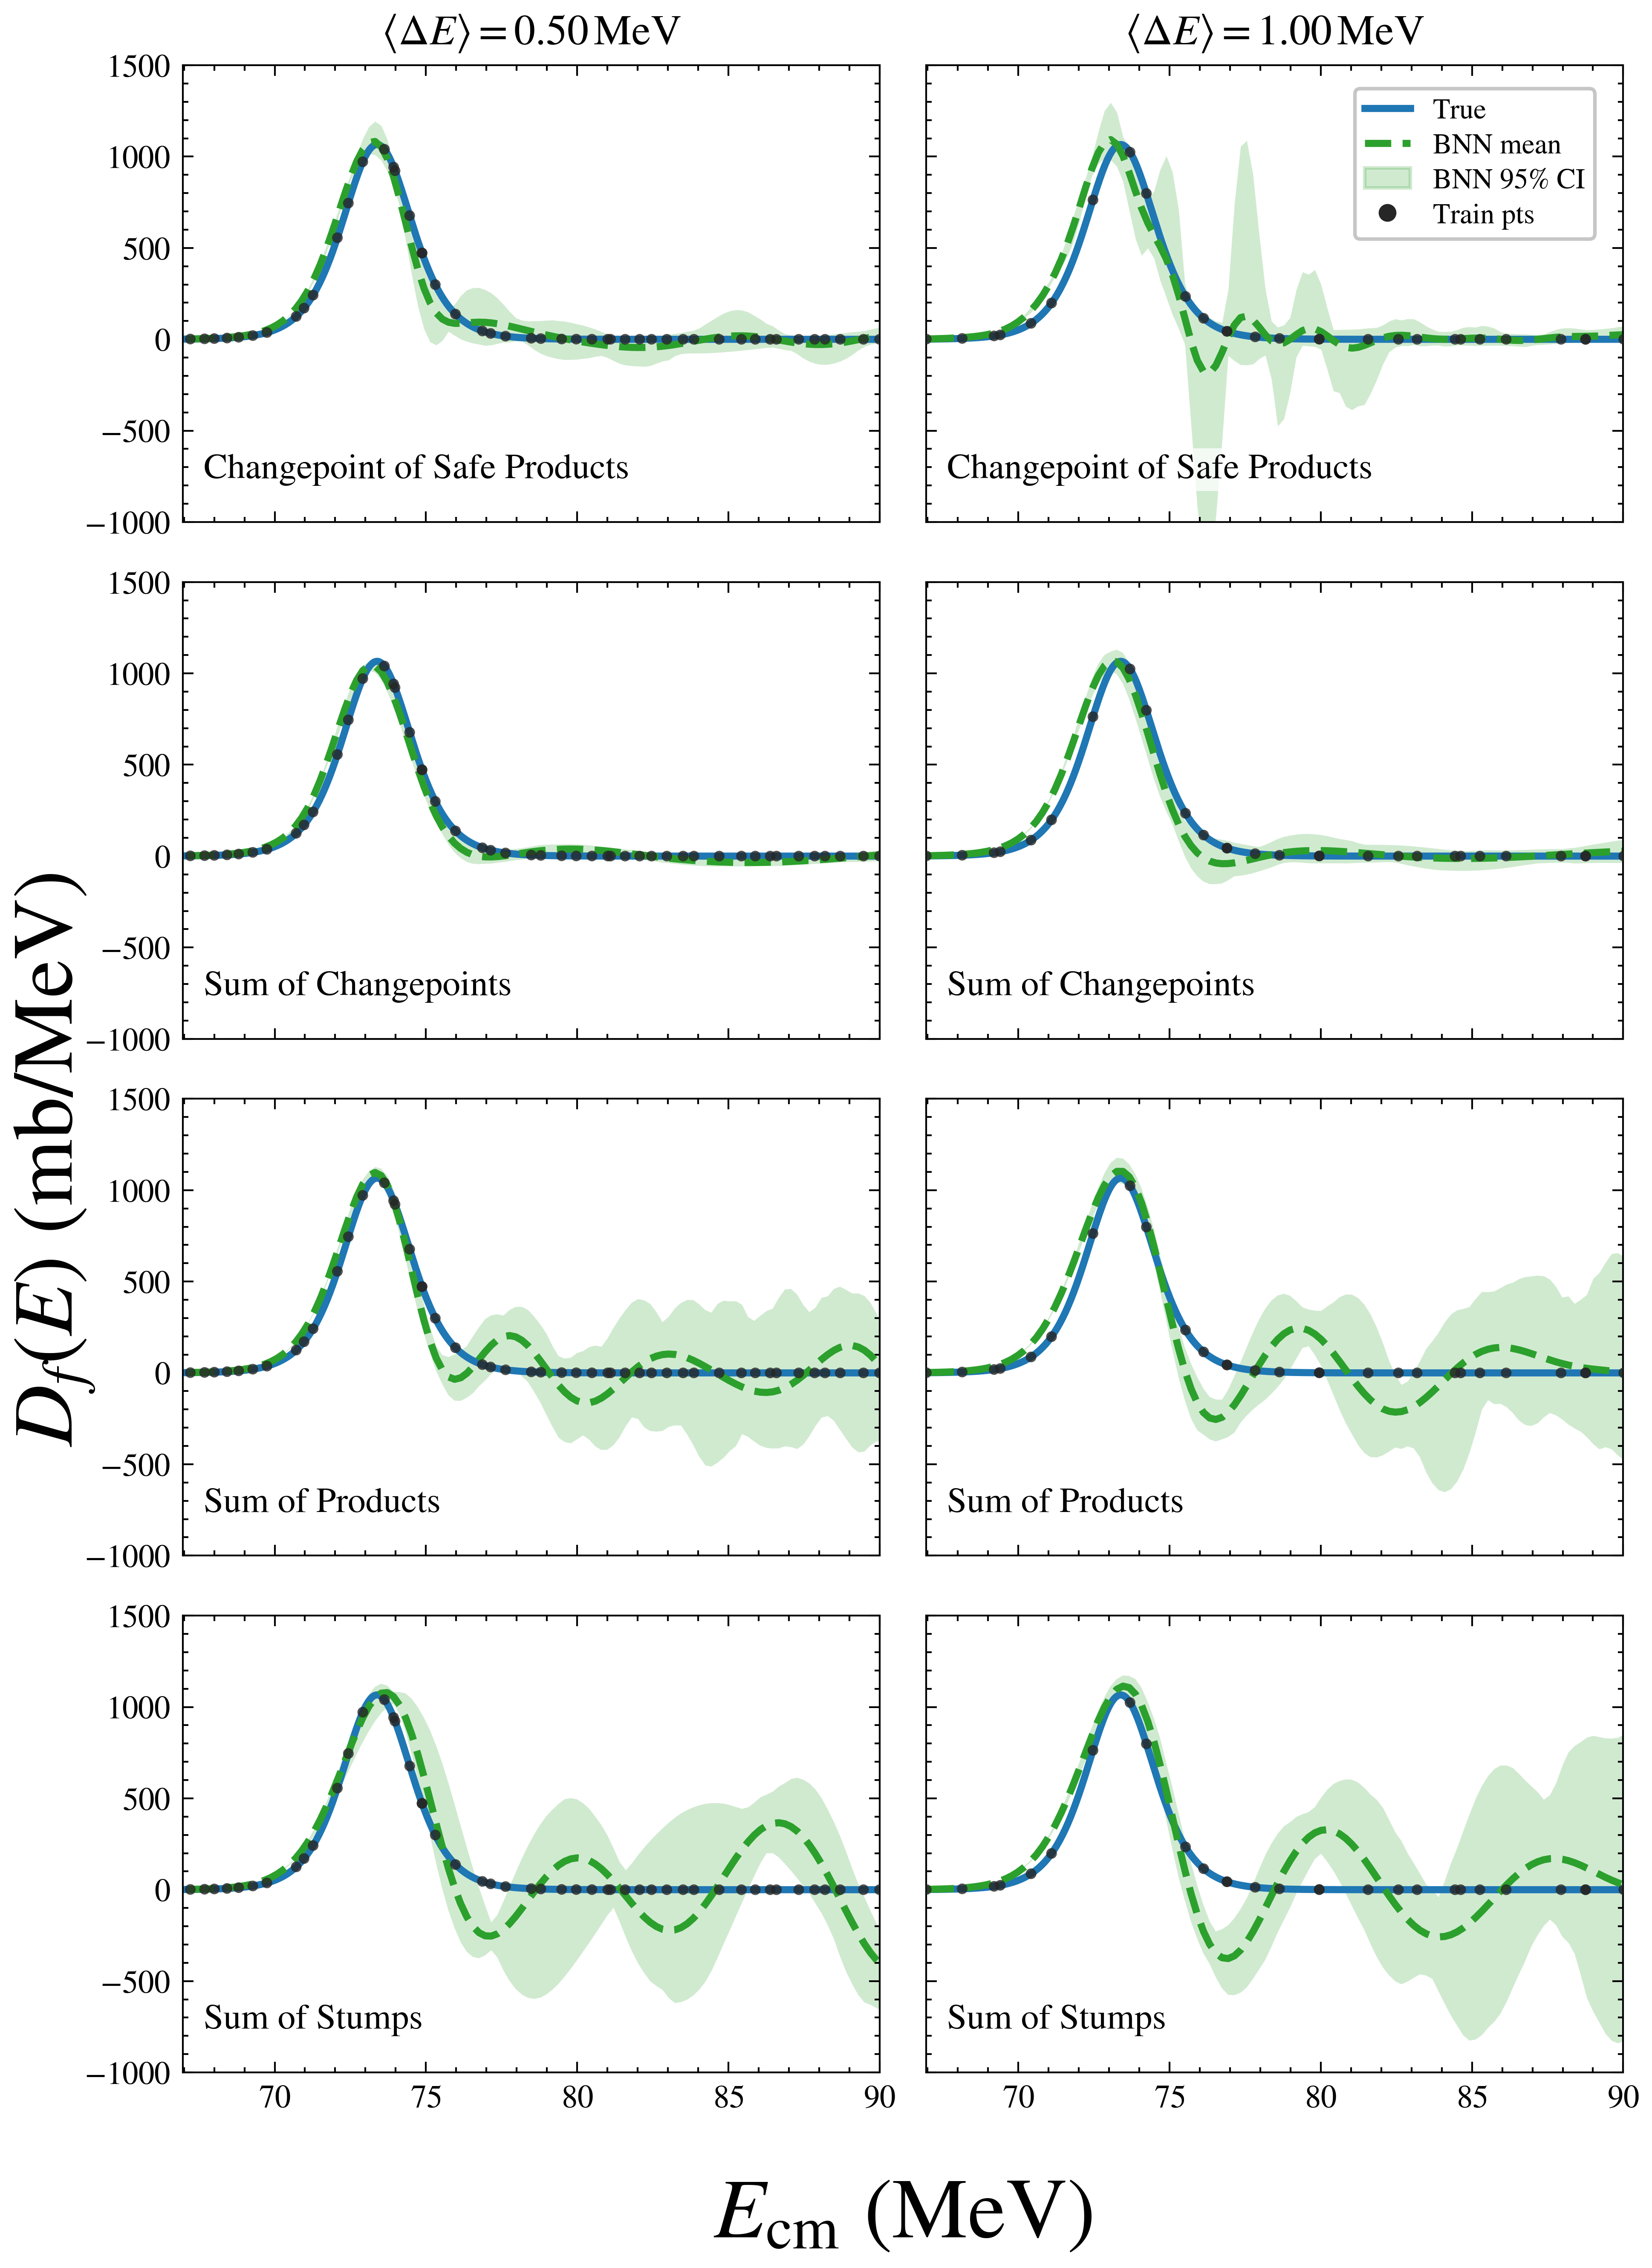

In [8]:
bnn_cv_05_log = load_bnn_case("E_cv_05_log", "E_tr_cv_0.50.npy", "E_dist_cv.npy")
bnn_cv_05_1mev_log = load_bnn_case("E_cv_05_1MEV_log", "E_tr_cv_0.50_1MEV.npy", "E_dist_cv_1MEV.npy")

plot_bnn_comparison_grid(
    [
        (rf"$\langle\Delta E\rangle = 0.50\,\mathrm{{MeV}}$", bnn_cv_05_log),
        (rf"$\langle\Delta E\rangle = 1.00\,\mathrm{{MeV}}$", bnn_cv_05_1mev_log),
    ],
    PLOT_DIR / "autobnn_irregularity_spacing_grid_log.png",
    suptitle=None,
    panel_label_loc="lower left",
)


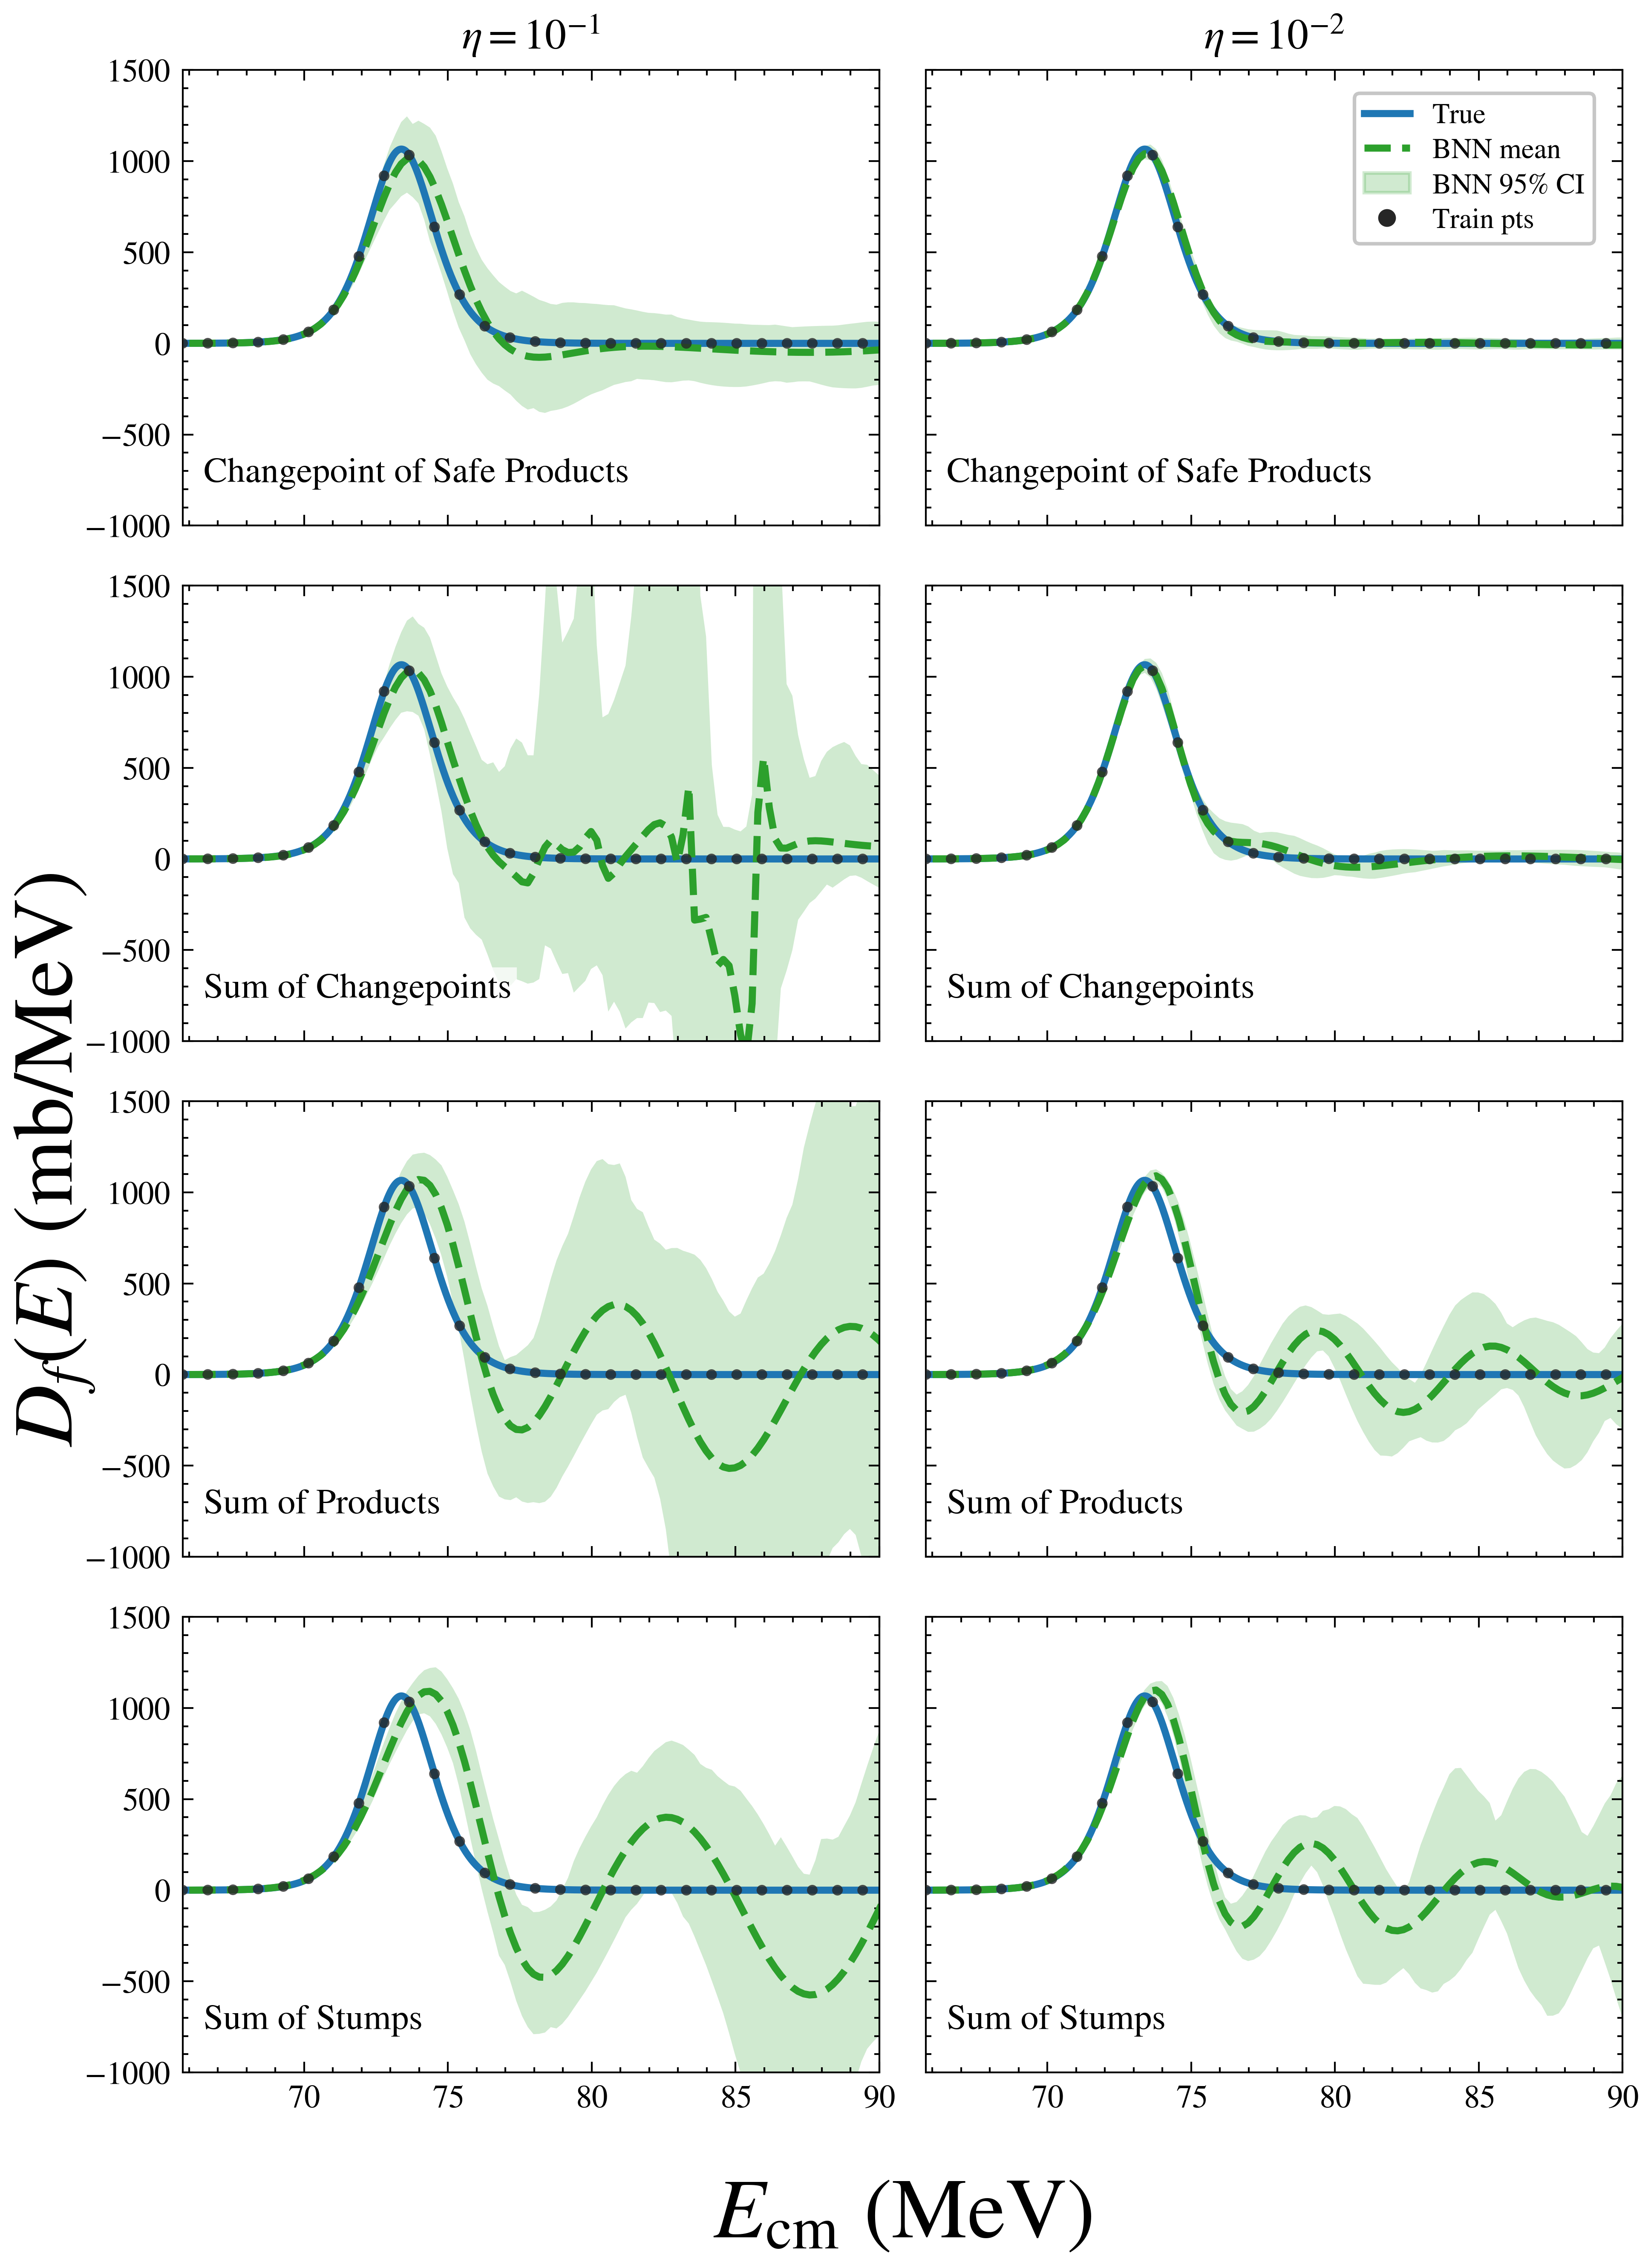

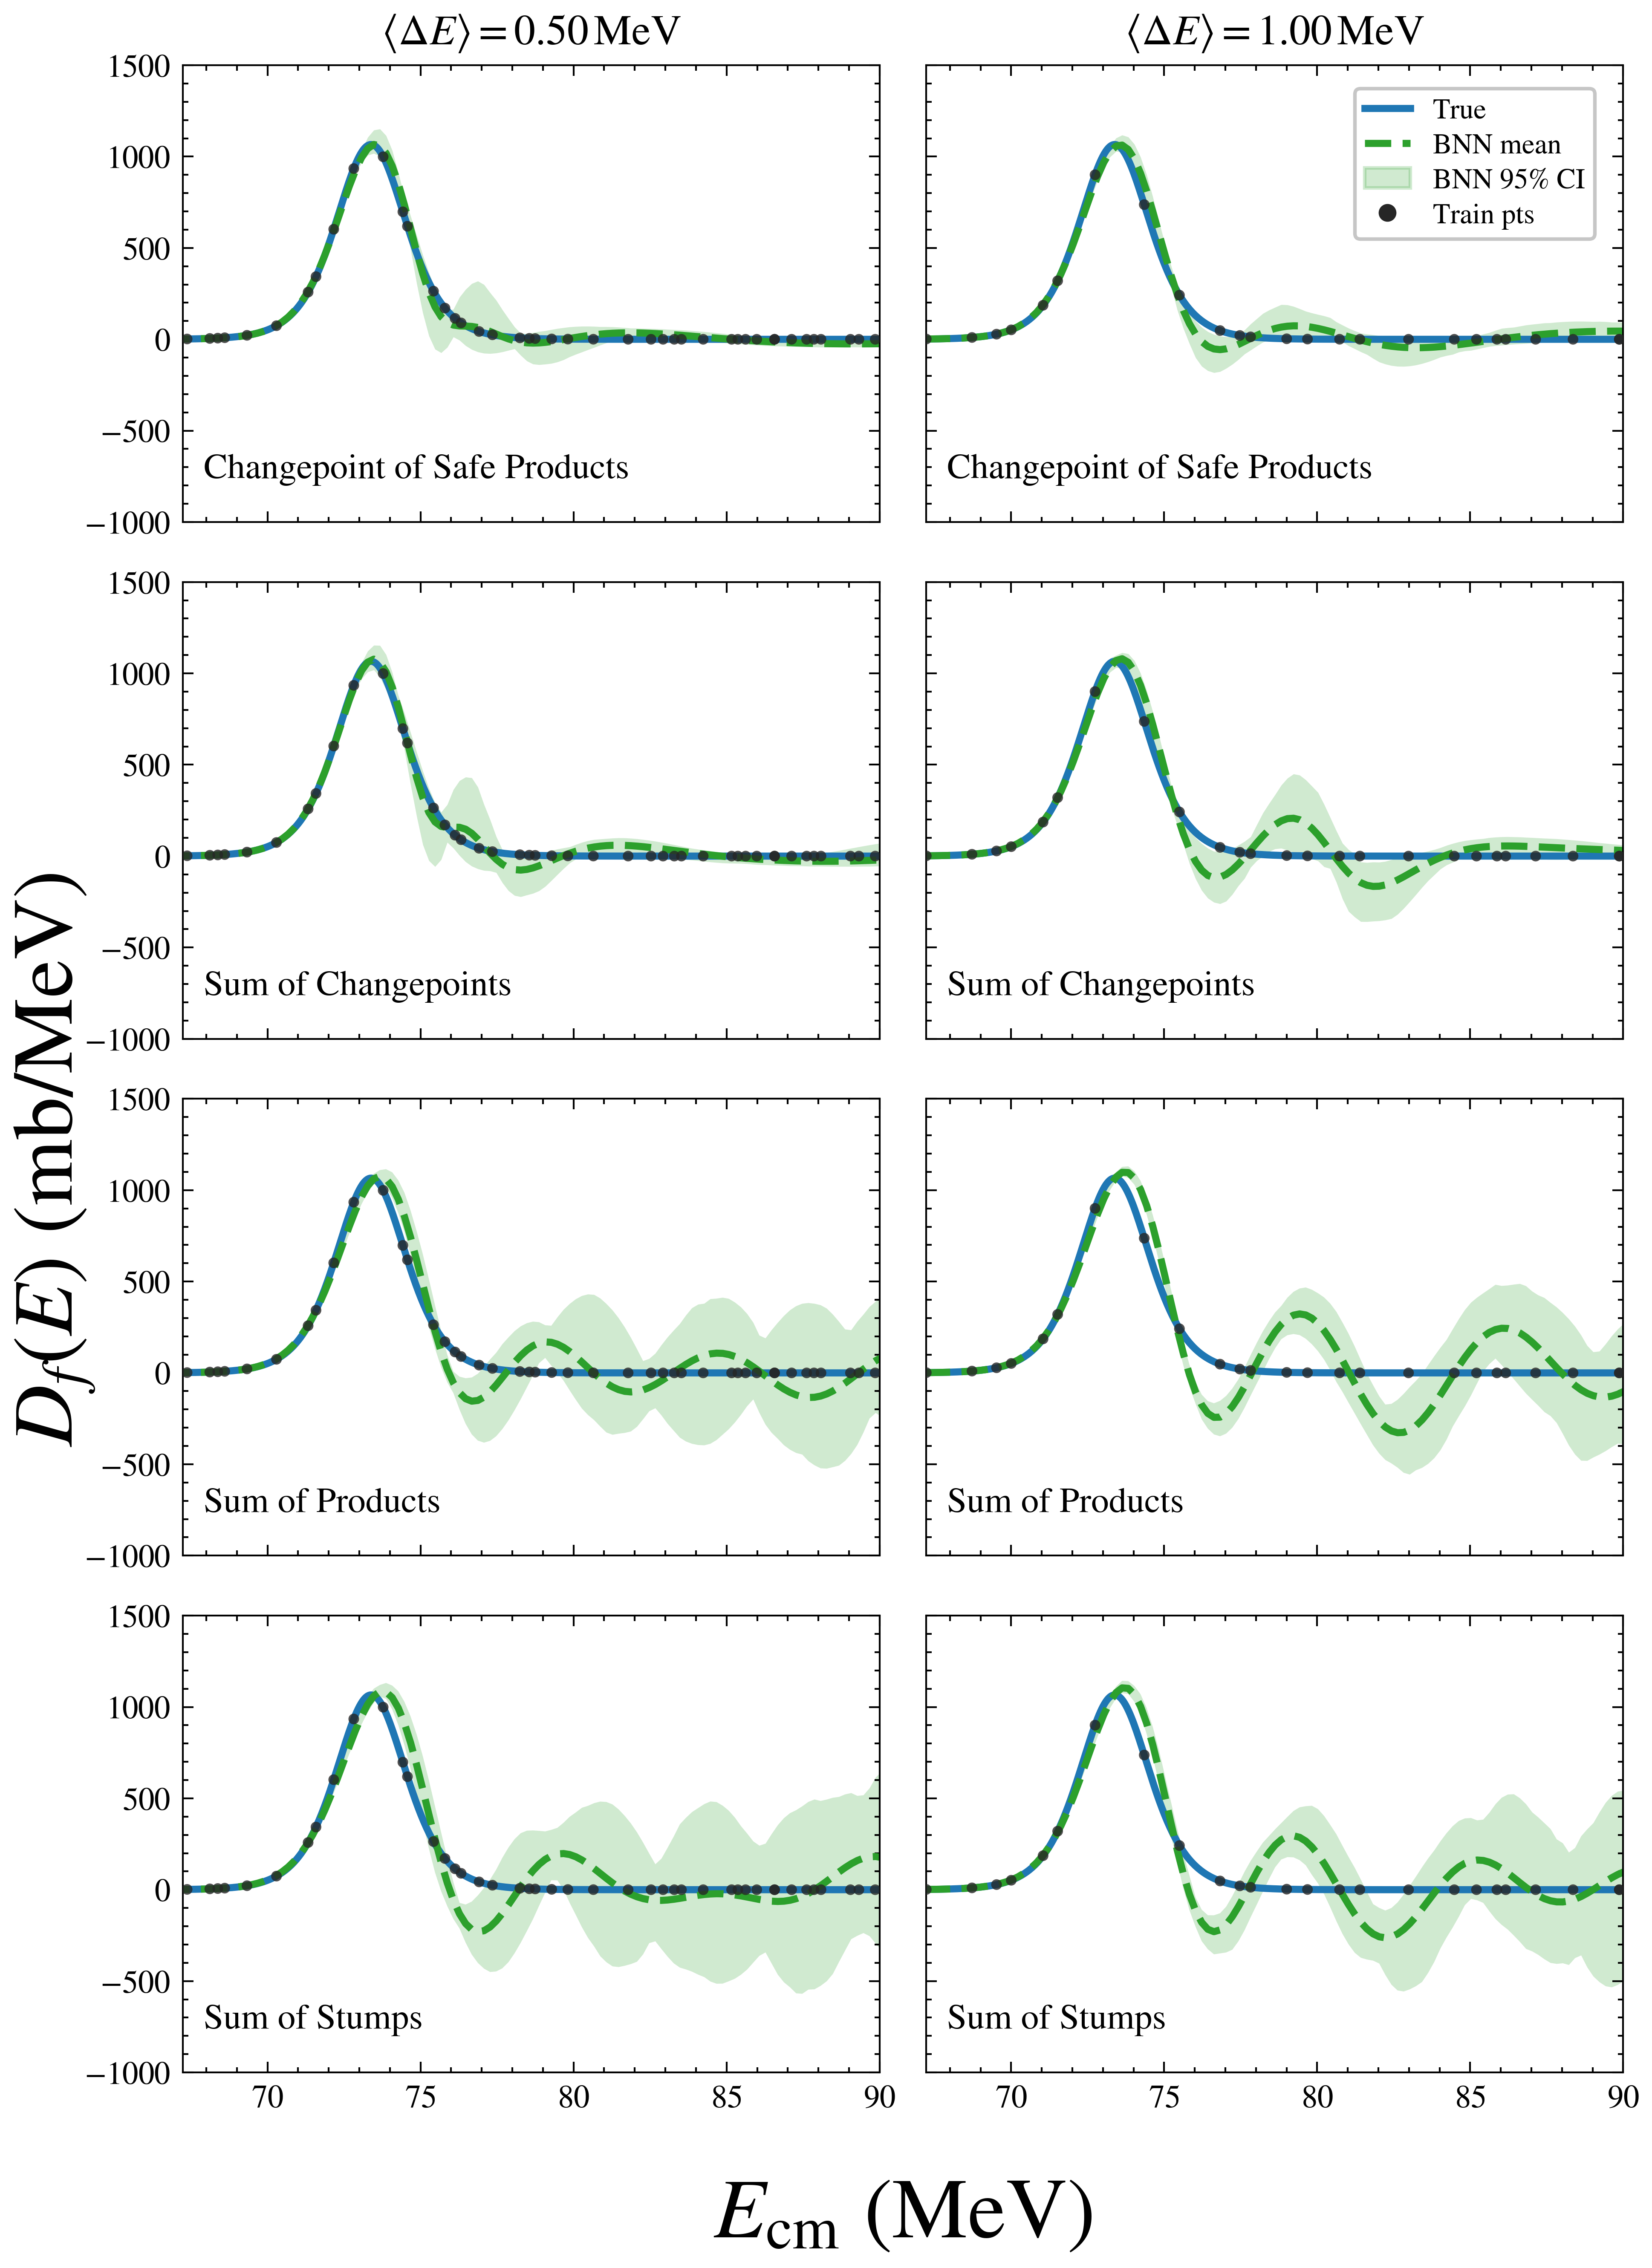

In [9]:
# Replacement calculations for the last two BNN comparison figures using the D3-penalized rerun.
import os
import h5py

BNN_D3LAM1E1_RESULTS = PROJECT_ROOT / "data" / "results" / "bnn_data_analysis_models_d3lam1e1"
BNN_D3LAM1E1_PREFIX = "bnn_data_analysis_4curves"
BNN_D3LAM1E1_SUFFIX = "bnn_d3lam1e1"


def _first_h5_group(h5_file):
    return h5_file[sorted(h5_file.keys(), key=lambda key: int(key) if key.isdigit() else key)[0]]


def bnn_d3lam1e1_result_path(case_slug, model_slug):
    filename = f"{BNN_D3LAM1E1_PREFIX}_{case_slug}_{model_slug}_{BNN_D3LAM1E1_SUFFIX}.h5"
    return os.path.join(BNN_D3LAM1E1_RESULTS, filename)


def load_bnn_d3lam1e1_case(case_slug):
    preds = {}
    E_pred_by_model = {}
    E_train = None

    for model_name, model_slug in MODEL_SPECS:
        with h5py.File(bnn_d3lam1e1_result_path(case_slug, model_slug), "r") as f:
            group = _first_h5_group(f)
            preds[model_name] = group["d2_samples"][()]
            E_pred_by_model[model_name] = group["x_pred"][()]
            if E_train is None:
                E_train = group["E_data"][()]

    return {
        "folder": case_slug,
        "E_train": E_train,
        "E_pred": next(iter(E_pred_by_model.values())),
        "E_pred_by_model": E_pred_by_model,
        "preds": preds,
    }


def plot_bnn_comparison_grid_by_model_x(column_specs, outfile, suptitle=None, panel_label_loc="upper left"):
    nrows, ncols = len(MODEL_SPECS), len(column_specs)
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.2, 2.35 * nrows), sharex=True, sharey=True)
    axes = np.asarray(axes).reshape(nrows, ncols)

    for col, (column_title, case) in enumerate(column_specs):
        axes[0, col].set_title(column_title, fontsize=12)
        E_train = case["E_train"]
        true_d_train = np.interp(E_train, E_fine, true_d)
        for row, (model_name, _) in enumerate(MODEL_SPECS):
            ax = axes[row, col]
            E_pred = case.get("E_pred_by_model", {}).get(model_name, case["E_pred"])
            preds = case["preds"][model_name]
            d_mean = preds.mean(axis=0)
            d_low, d_high = np.percentile(preds, [2.5, 97.5], axis=0)

            ax.plot(E_fine, true_d, lw=2.0, color=TRUE_COLOR)
            ax.plot(E_pred, d_mean, lw=2.0, ls="--", color=BNN_COLOR)
            ax.fill_between(E_pred, d_low, d_high, color=BNN_COLOR, alpha=BAND_ALPHA, linewidth=0)
            ax.scatter(E_train, true_d_train, s=9, color=DATA_COLOR, alpha=0.8, edgecolor="none", zorder=5)
            add_panel_label(ax, model_name, loc=panel_label_loc)
            ax.set_xlim(E_train[0], 90)
            ax.set_ylim(-1000, 1500)
            ax.tick_params(labelsize=9)

    if suptitle:
        fig.suptitle(suptitle, fontsize=12, y=0.995)
    fig.supylabel(r"$D_f(E)$ (mb/MeV)", fontsize=SHARED_LABEL_FONTSIZE, x=SHARED_YLABEL_X)
    add_inset_legend(axes[0, -1], bnn_legend_handles())
    fig.tight_layout(rect=[0.06, 0.09, 1, 0.965 if suptitle else 0.99])
    left = axes[-1, 0].get_position().x0
    right = axes[-1, -1].get_position().x1
    fig.text(0.5 * (left + right), SHARED_XLABEL_Y, r"$E_{\mathrm{cm}}$ (MeV)", ha="center", va="center", fontsize=SHARED_LABEL_FONTSIZE)
    fig.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


bnn_d3_log_20_1e1 = load_bnn_d3lam1e1_case("E_20_1e-1_log")
bnn_d3_log_20_1e2 = load_bnn_d3lam1e1_case("E_20_1e-2_log")

plot_bnn_comparison_grid_by_model_x(
    [
        (rf"$\eta = 10^{{-1}}$", bnn_d3_log_20_1e1),
        (rf"$\eta = 10^{{-2}}$", bnn_d3_log_20_1e2),
    ],
    PLOT_DIR / "autobnn_noise_ratio_grid_log.png",
    suptitle=None,
    panel_label_loc="lower left",
)

bnn_d3_cv_05_log = load_bnn_d3lam1e1_case("E_cv_05_log")
bnn_d3_cv_05_1mev_log = load_bnn_d3lam1e1_case("E_cv_05_1MEV_log")

plot_bnn_comparison_grid_by_model_x(
    [
        (rf"$\langle\Delta E\rangle = 0.50\,\mathrm{{MeV}}$", bnn_d3_cv_05_log),
        (rf"$\langle\Delta E\rangle = 1.00\,\mathrm{{MeV}}$", bnn_d3_cv_05_1mev_log),
    ],
    PLOT_DIR / "autobnn_irregularity_spacing_grid_log.png",
    suptitle=None,
    panel_label_loc="lower left",
)
